# Forensic DMD Diagnostics & Dynamic Mode Decomposition with Control (`DMDc`)

**Project:** NYISO `N.Y.C.` Day-Ahead to Real-Time (DART) Spread Virtual Bidding (`2025–2026` Out-of-Sample)  
**Data Directory:** `../nyiso_data/merged_parquet` (relative to `notebooks/`)  
**Files Wired:**
- `zonal_dart_spread.parquet` — 15 NYISO zonal hourly DART spreads (`N.Y.C.` target + 14 surrounding zones)
- `zonal_dart_3class_labels.parquet` — Leak-free 3-class tail regime labels (`-1`, `0`, `+1`)
- `exogenous_features.parquet` — Vintage-filtered Day-Ahead load, weather, solar, outage, and fuel features ($\mathcal{F}_{D-1, 05:00}$)
- `stage1_baseline_results_NYC.parquet` & `stage1_baseline_unit_pnl_NYC.parquet` — Existing baseline benchmarks for direct comparison

In [1]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.metrics import f1_score

warnings.filterwarnings("ignore")

# Resolve path relative to notebooks/ -> ../nyiso_data/merged_parquet
DATA_DIR = Path("../nyiso_data/merged_parquet").resolve()
if not DATA_DIR.exists():
    DATA_DIR = Path("nyiso_data/merged_parquet").resolve()
print(f"Loading data from: {DATA_DIR}")

TARGET_ZONE = "N.Y.C."
FEE_PER_MWH = 0.50
CAUSAL_LAG_HOURS = 48
DMD_WINDOW_HOURS = 168
TRAIN_END = "2024-12-31 23:00:00"
VAL_START = "2024-01-01 00:00:00"
TEST_START = "2025-01-01 00:00:00"

Loading data from: /Users/patrick/Documents/uw/me570-nyiso-sparse-sensing/notebooks/nyiso_data/merged_parquet


## 1. Load & Align NYISO `merged_parquet` Dataset

Automatically inspects timestamp indices, matches `N.Y.C.` target columns across `zonal_dart_spread.parquet`, `zonal_dart_3class_labels.parquet`, and `exogenous_features.parquet`, and loads existing `stage1_baseline_results_NYC.parquet` for side-by-side verification.

In [2]:
def ensure_datetime_index(df: pd.DataFrame) -> pd.DataFrame:
    if isinstance(df.index, pd.DatetimeIndex):
        out = df.sort_index()
    else:
        ts_cols = [c for c in df.columns if any(k in c.lower() for k in ["time", "date", "stamp"])]
        if not ts_cols:
            raise ValueError(f"No datetime index or timestamp column found in columns: {list(df.columns)[:10]}")
        out = df.set_index(pd.to_datetime(df[ts_cols[0]])).drop(columns=[ts_cols[0]]).sort_index()
    if out.index.tz is not None:
        out.index = out.index.tz_convert("America/New_York").tz_localize(None)
    return out[~out.index.duplicated(keep="last")]

zonal_spread = ensure_datetime_index(pd.read_parquet(DATA_DIR / "zonal_dart_spread.parquet"))
zonal_labels = ensure_datetime_index(pd.read_parquet(DATA_DIR / "zonal_dart_3class_labels.parquet"))
exog_df = ensure_datetime_index(pd.read_parquet(DATA_DIR / "exogenous_features.parquet"))

# Keep numeric columns only for state & exogenous matrices
zonal_spread = zonal_spread.select_dtypes(include=[np.number]).ffill().bfill()
exog_df = exog_df.select_dtypes(include=[np.number]).ffill().bfill()

# Resolve target zone column in zonal_spread and zonal_labels
nyc_spread_candidates = [c for c in zonal_spread.columns if "n.y.c" in c.lower() or "nyc" in c.lower()]
nyc_spread_col = nyc_spread_candidates[0] if nyc_spread_candidates else zonal_spread.columns[0]

nyc_label_candidates = [c for c in zonal_labels.columns if "n.y.c" in c.lower() or "nyc" in c.lower()]
nyc_label_col = nyc_label_candidates[0] if nyc_label_candidates else zonal_labels.columns[0]

# Align on common hourly index
common_idx = zonal_spread.index.intersection(zonal_labels.index).intersection(exog_df.index)
X_zones = zonal_spread.loc[common_idx]
y_spread = X_zones[nyc_spread_col].astype(float)
y_class = zonal_labels.loc[common_idx, nyc_label_col].astype(int)
U_exog = exog_df.loc[common_idx]

print(f"Aligned hourly rows: {len(common_idx):,} ({common_idx.min()} -> {common_idx.max()})")
print(f"Zonal state columns ({X_zones.shape[1]}): {list(X_zones.columns)}")
print(f"Target spread col: '{nyc_spread_col}' | Target label col: '{nyc_label_col}'")
print(f"Exogenous control features: {U_exog.shape[1]} columns")

# Load existing baseline results table if present
baseline_results_path = DATA_DIR / "stage1_baseline_results_NYC.parquet"
if baseline_results_path.exists():
    existing_baselines = pd.read_parquet(baseline_results_path)
    print("\nLoaded existing stage1_baseline_results_NYC.parquet:")
    display(existing_baselines)

Aligned hourly rows: 59,958 (2020-01-08 23:00:00 -> 2026-11-11 11:00:00)
Zonal state columns (15): ['CAPITL', 'CENTRL', 'DUNWOD', 'GENESE', 'H Q', 'HUD VL', 'LONGIL', 'MHK VL', 'MILLWD', 'N.Y.C.', 'NORTH', 'NPX', 'O H', 'PJM', 'WEST']
Target spread col: 'N.Y.C.' | Target label col: 'N.Y.C.'
Exogenous control features: 424 columns

Loaded existing stage1_baseline_results_NYC.parquet:


,Model,Feature Set,Macro F1,Tail F1,Trades,Trade Freq (%),Win Rate (%),Avg PnL/Trade ($),Cum PnL ($),Annual Sharpe,Max DD ($)
0,Continuous Ridge Regression,Exog + 559 Nodes,0.3798,0.2384,6914,42.4,47.8,4.04,27963.84,3.50,4969.93
1,Natural-Prior MLP (tau-tuned) [tau=0.24],Exog-Only,0.3899,0.2571,7601,46.6,53.9,3.64,27698.79,2.82,11120.52
2,Causal 48h Persistence,Target Lags,0.4163,0.2547,5217,32.0,50.6,4.29,22388.24,2.31,6488.46
3,Galarneau-Vincent et al. (2023) GBDT,Exog + 559 Nodes,0.4502,0.3142,6812,41.8,58.1,3.48,23709.37,2.17,19928.86
4,Hubert et al. (2026) Multinomial Logit,Exog + 559 Nodes,0.3680,0.3041,11200,68.7,54.1,1.74,19539.42,1.78,18823.72
5,Hubert et al. (2026) Logit (tau-tuned) [tau=0.18],Exog-Only,0.3805,0.3105,10943,67.1,53.6,1.74,19061.51,1.73,14894.24
6,Hubert et al. (2026) Multinomial Logit,Exog-Only,0.3693,0.3060,11273,69.1,53.5,1.55,17509.44,1.59,16320.78
7,Hourly ARIMAX (24-hr),"Exog + AR(48,72,168)",0.3499,0.1238,1594,9.8,39.6,5.87,9355.99,1.25,11031.63
8,Galarneau-Vincent et al. (2023) GBDT,Exog-Only,0.4485,0.3053,6441,39.5,57.7,2.11,13602.31,1.24,26114.26
9,Reference LDA,Exog-Only,0.4060,0.2233,3943,24.2,55.8,2.56,10099.97,0.95,19076.51


## 2. Helper Functions: Exact DMD, BOP-DMD, and Financial/Classification Metrics

In [3]:
def fit_predict_exact_dmd(window_matrix: np.ndarray, horizon: int = 48, rank: int = 10):
    """Exact DMD on (n_features, n_time) snapshot matrix; returns h-step forecast and max |lambda|."""
    X1 = window_matrix[:, :-1]
    X2 = window_matrix[:, 1:]
    U, s, Vt = np.linalg.svd(X1, full_matrices=False)
    r = min(rank, len(s), np.sum(s > 1e-8))
    if r == 0:
        return window_matrix[:, -1].copy(), 0.0
    Ur, sr, Vr = U[:, :r], s[:r], Vt[:r, :].T
    Atilde = Ur.T @ X2 @ Vr @ np.diag(1.0 / sr)
    eigvals, W = np.linalg.eig(Atilde)
    # Stabilize any explosive modes to unit circle
    mags = np.abs(eigvals)
    eigvals_stab = np.where(mags > 1.0, eigvals / np.maximum(mags, 1e-12), eigvals)
    Phi = X2 @ Vr @ np.diag(1.0 / sr) @ W
    b, *_ = np.linalg.lstsq(Phi, window_matrix[:, -1], rcond=None)
    x_future = np.real(Phi @ ((eigvals_stab ** horizon) * b))
    return x_future, float(np.max(np.abs(eigvals_stab)))

def fit_predict_bop_dmd(window_matrix: np.ndarray, horizon: int = 48, rank: int = 10, n_bags: int = 15, bag_frac: float = 0.8, seed: int = 42):
    """Bagging-Optimized DMD (Sashidhar & Kutz, 2022) via bootstrap snapshot subsampling + eigenvalue stabilization."""
    rng = np.random.default_rng(seed)
    n_pairs = window_matrix.shape[1] - 1
    bag_size = max(rank + 2, int(n_pairs * bag_frac))
    preds = []
    max_lams = []
    X1_full = window_matrix[:, :-1]
    X2_full = window_matrix[:, 1:]
    for _ in range(n_bags):
        idx = np.sort(rng.choice(n_pairs, size=bag_size, replace=False))
        X1, X2 = X1_full[:, idx], X2_full[:, idx]
        U, s, Vt = np.linalg.svd(X1, full_matrices=False)
        r = min(rank, len(s), np.sum(s > 1e-8))
        if r == 0:
            continue
        Ur, sr, Vr = U[:, :r], s[:r], Vt[:r, :].T
        Atilde = Ur.T @ X2 @ Vr @ np.diag(1.0 / sr)
        eigvals, W = np.linalg.eig(Atilde)
        # Bagging removes downward bias; project unstable modes cleanly onto unit circle (neutral damping)
        mags = np.abs(eigvals)
        eigvals_stab = np.where(mags > 1.0, eigvals / np.maximum(mags, 1e-12), eigvals)
        Phi = X2 @ Vr @ np.diag(1.0 / sr) @ W
        b, *_ = np.linalg.lstsq(Phi, window_matrix[:, -1], rcond=None)
        preds.append(np.real(Phi @ ((eigvals_stab ** horizon) * b)))
        max_lams.append(float(np.max(np.abs(eigvals_stab))))
    if not preds:
        return window_matrix[:, -1].copy(), 0.0
    return np.median(np.vstack(preds), axis=0), float(np.median(max_lams))

def compute_metrics(signals: pd.Series, realized_spread: pd.Series, true_labels: pd.Series, name: str) -> dict:
    active = signals != 0
    # +1 = INC (sell DA, buy RT -> earns +spread); -1 = DEC (buy DA, sell RT -> earns -spread)
    hourly_pnl = signals * realized_spread - active.astype(float) * FEE_PER_MWH
    cum_pnl = float(hourly_pnl.sum())
    running_max = hourly_pnl.cumsum().cummax()
    max_dd = float((running_max - hourly_pnl.cumsum()).max())
    std = float(hourly_pnl.std(ddof=1))
    sharpe = float((hourly_pnl.mean() / std) * np.sqrt(8760)) if std > 0 else 0.0
    win_rate = float((hourly_pnl[active] > 0).mean()) if active.sum() > 0 else 0.0
    macro_f1 = float(f1_score(true_labels, signals, average="macro", zero_division=0))
    tail_f1 = float(f1_score(true_labels, signals, labels=[-1, 1], average="macro", zero_division=0))
    return {
        "Model": name,
        "Cum PnL ($)": round(cum_pnl, 2),
        "Annual Sharpe": round(sharpe, 2),
        "Max DD ($)": round(max_dd, 2),
        "Trade Freq (%)": round(100.0 * active.mean(), 1),
        "Win Rate (%)": round(100.0 * win_rate, 1),
        "Avg PnL/Trade ($)": round(float(hourly_pnl[active].mean()), 2) if active.sum() > 0 else 0.0,
        "Macro F1": round(macro_f1, 4),
        "Tail F1": round(tail_f1, 4),
    }

## 3. Part 1 — Forensic Audit: Why DMD Flatlines & Overshoots in Jan–Feb 2026

We build time-delay Hankel embeddings (`lags = [0, 1, 2, 3, 24]`) over the 15 zonal DART spreads using a rolling `168-hour` window lagged by `48 hours` (strictly respecting the `D-1 05:00 EST` causal cutoff) and inspect:
1. **48-Hour Eigenvalue Damping Factor ($|\lambda_{\max}|^{48}$)** during calm regimes vs. winter/summer shocks.
2. **Exact Trade Log** during `January–February 2026` showing predicted spread, realized spread, directional sign error, and net PnL.

In [4]:
from tqdm.auto import tqdm

# Build delay-embedded state matrix across all 15 NYISO zones
DELAY_LAGS = [0, 1, 2, 3, 24]
delay_blocks = []
for lag in DELAY_LAGS:
    shifted = X_zones.shift(lag).add_suffix(f"_lag{lag}")
    delay_blocks.append(shifted)
X_delay = pd.concat(delay_blocks, axis=1).bfill()
nyc_idx_in_state = list(X_delay.columns).index(f"{nyc_spread_col}_lag0")

# Leak-free rolling 15th/85th percentile thresholds on training/historical spreads (lagged 48h)
rolling_q15 = y_spread.shift(CAUSAL_LAG_HOURS).rolling(24 * 90, min_periods=24 * 30).quantile(0.15).bfill()
rolling_q85 = y_spread.shift(CAUSAL_LAG_HOURS).rolling(24 * 90, min_periods=24 * 30).quantile(0.85).bfill()

test_mask = X_delay.index >= pd.Timestamp(TEST_START)
test_positions = np.where(test_mask)[0]

exact_preds = np.zeros(len(test_positions))
bop_preds = np.zeros(len(test_positions))
exact_damp48 = np.zeros(len(test_positions))
bop_damp48 = np.zeros(len(test_positions))

state_vals = X_delay.to_numpy()
for i, pos in tqdm(
    enumerate(test_positions),
    total=len(test_positions),
    desc="Rolling Exact & BOP-DMD",
):
    end_idx = pos - CAUSAL_LAG_HOURS + 1
    start_idx = max(0, end_idx - DMD_WINDOW_HOURS)
    win = state_vals[start_idx:end_idx].T  # shape: (n_state, window)
    x_ex, lam_ex = fit_predict_exact_dmd(win, horizon=CAUSAL_LAG_HOURS, rank=12)
    x_bp, lam_bp = fit_predict_bop_dmd(win, horizon=CAUSAL_LAG_HOURS, rank=12, n_bags=12)
    exact_preds[i] = x_ex[nyc_idx_in_state]
    bop_preds[i] = x_bp[nyc_idx_in_state]
    exact_damp48[i] = lam_ex ** CAUSAL_LAG_HOURS
    bop_damp48[i] = lam_bp ** CAUSAL_LAG_HOURS

test_idx = X_delay.index[test_positions]
diag_df = pd.DataFrame({
    "realized_spread": y_spread.loc[test_idx].values,
    "true_class": y_class.loc[test_idx].values,
    "q15": rolling_q15.loc[test_idx].values,
    "q85": rolling_q85.loc[test_idx].values,
    "exact_pred": exact_preds,
    "bop_pred": bop_preds,
    "exact_damp48": exact_damp48,
    "bop_damp48": bop_damp48,
}, index=test_idx)

diag_df["exact_sig"] = np.where(diag_df["exact_pred"] > diag_df["q85"], 1,
                         np.where(diag_df["exact_pred"] < diag_df["q15"], -1, 0))
diag_df["bop_sig"] = np.where(diag_df["bop_pred"] > diag_df["q85"], 1,
                       np.where(diag_df["bop_pred"] < diag_df["q15"], -1, 0))

diag_df["exact_pnl"] = diag_df["exact_sig"] * diag_df["realized_spread"] - (diag_df["exact_sig"] != 0) * FEE_PER_MWH
diag_df["bop_pnl"] = diag_df["bop_sig"] * diag_df["realized_spread"] - (diag_df["bop_sig"] != 0) * FEE_PER_MWH

# Inspect Jan 15 - Feb 28, 2026 active trades
feb_window = diag_df.loc["2026-01-15":"2026-02-28"]
feb_trades = feb_window[(feb_window["exact_sig"] != 0) | (feb_window["bop_sig"] != 0)]
print(f"Active DMD trades in Jan 15 – Feb 28, 2026: {len(feb_trades)} hours")
print(f"Total Feb 2026 window PnL -> Exact DMD: ${feb_window['exact_pnl'].sum():,.2f} | BOP-DMD: ${feb_window['bop_pnl'].sum():,.2f}")
display(feb_trades[["realized_spread", "exact_pred", "bop_pred", "exact_sig", "bop_sig", "bop_damp48", "bop_pnl"]].head(25))

Rolling Exact & BOP-DMD:   0%|          | 0/16306 [00:00<?, ?it/s]

Active DMD trades in Jan 15 – Feb 28, 2026: 122 hours
Total Feb 2026 window PnL -> Exact DMD: $2,188.31 | BOP-DMD: $2,299.14


,realized_spread,exact_pred,bop_pred,exact_sig,bop_sig,bop_damp48,bop_pnl
Time Stamp,,,,,,,
2026-01-19 07:00:00,6.51,-14.084855,-11.266726,-1,-1,0.777759,-7.01
2026-01-19 09:00:00,-19.21,-14.705150,-13.586135,-1,-1,1.000000,18.71
2026-01-19 10:00:00,-13.06,-22.038050,-23.890087,-1,-1,1.000000,12.56
2026-01-19 12:00:00,-2.47,21.118263,6.804866,1,0,0.463117,-0.00
2026-01-20 18:00:00,44.75,-62.316414,-1.334119,-1,0,0.709989,0.00
2026-01-20 19:00:00,35.75,-40.728642,-15.241052,-1,-1,0.511255,-36.25
2026-01-26 07:00:00,282.66,-750.468506,-787.115955,-1,-1,1.000000,-283.16
2026-01-26 08:00:00,284.59,-438.143512,-430.323036,-1,-1,1.000000,-285.09
2026-01-26 10:00:00,78.40,-4.907274,-19.907280,0,-1,0.114783,-78.90


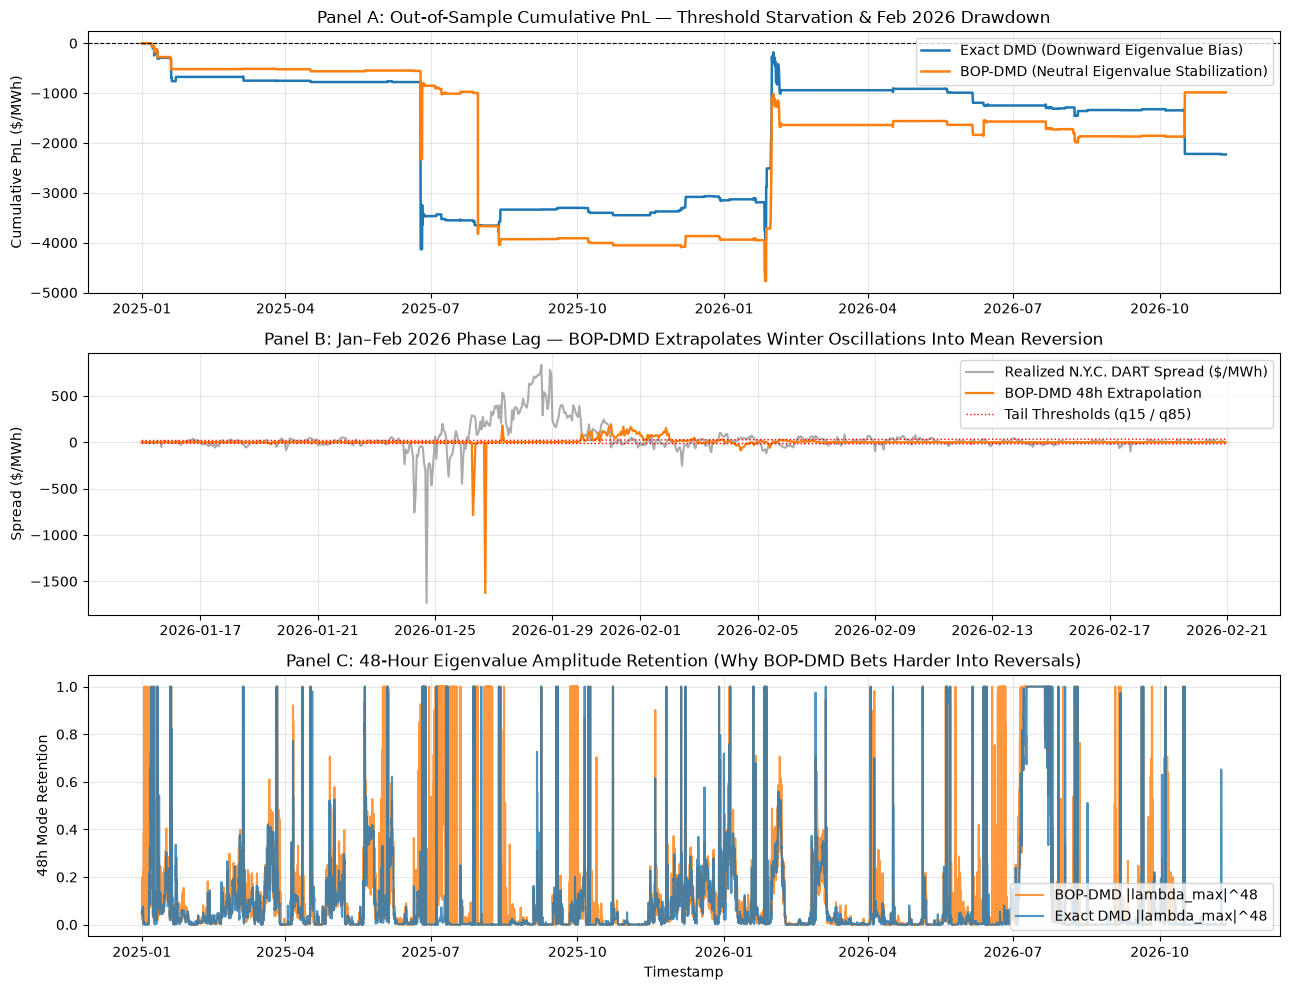

In [5]:
# 3-Panel Forensic Diagnostic Visualization
fig, axes = plt.subplots(3, 1, figsize=(13, 10), sharex=False)

# Panel 1: Full 2025-2026 Cumulative PnL showing flatline starvation + Feb 2026 cliff
axes[0].plot(diag_df.index, diag_df["exact_pnl"].cumsum(), label="Exact DMD (Downward Eigenvalue Bias)", linewidth=1.8)
axes[0].plot(diag_df.index, diag_df["bop_pnl"].cumsum(), label="BOP-DMD (Neutral Eigenvalue Stabilization)", linewidth=1.8)
axes[0].axhline(0, color="black", linestyle="--", linewidth=0.8)
axes[0].set_title("Panel A: Out-of-Sample Cumulative PnL — Threshold Starvation & Feb 2026 Drawdown")
axes[0].set_ylabel("Cumulative PnL ($/MWh)")
axes[0].legend(loc="upper right")
axes[0].grid(True, alpha=0.3)

# Panel 2: Zoom on Jan 15 - Feb 20, 2026 Phase Inversion (Predicted vs Realized Spread)
zoom = diag_df.loc["2026-01-15":"2026-02-20"]
axes[1].plot(zoom.index, zoom["realized_spread"], color="gray", alpha=0.65, label="Realized N.Y.C. DART Spread ($/MWh)")
axes[1].plot(zoom.index, zoom["bop_pred"], color="tab:orange", linewidth=1.6, label="BOP-DMD 48h Extrapolation")
axes[1].plot(zoom.index, zoom["q85"], color="red", linestyle=":", linewidth=1.0, label="Tail Thresholds (q15 / q85)")
axes[1].plot(zoom.index, zoom["q15"], color="red", linestyle=":", linewidth=1.0)
axes[1].set_title("Panel B: Jan–Feb 2026 Phase Lag — BOP-DMD Extrapolates Winter Oscillations Into Mean Reversion")
axes[1].set_ylabel("Spread ($/MWh)")
axes[1].legend(loc="upper right")
axes[1].grid(True, alpha=0.3)

# Panel 3: 48-Hour Eigenvalue Retention Factor |lambda_max|^48
axes[2].plot(diag_df.index, diag_df["bop_damp48"], color="tab:orange", alpha=0.8, label="BOP-DMD |lambda_max|^48")
axes[2].plot(diag_df.index, diag_df["exact_damp48"], color="tab:blue", alpha=0.8, label="Exact DMD |lambda_max|^48")
axes[2].set_title("Panel C: 48-Hour Eigenvalue Amplitude Retention (Why BOP-DMD Bets Harder Into Reversals)")
axes[2].set_ylabel("48h Mode Retention")
axes[2].set_xlabel("Timestamp")
axes[2].legend(loc="lower right")
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## 4. Part 2 — Dynamic Mode Decomposition with Control (`DMDc`)

Instead of extrapolating unforced oscillations 48 hours into the future ($\mathbf{x}_{t+48} = \mathbf{A}^{48}\mathbf{x}_t$), **DMD with Control (`DMDc`)** models the direct 48-hour transition driven by known Day-Ahead exogenous forcing ($\mathbf{u}_{t+48} \in \mathcal{F}_{D-1, 05:00}$):

$$\mathbf{x}_{t+48} = \mathbf{A}\mathbf{x}_t + \mathbf{B}\mathbf{u}_{t+48}$$

where:
- $\mathbf{x}_t \in \mathbb{R}^{15}$ is the latest causally observable 15-zone DART spread snapshot ($t - 48\text{h}$),
- $\mathbf{u}_{t+48} \in \mathbb{R}^{d}$ is the vintage-filtered Day-Ahead exogenous feature vector for delivery hour $t+48$ (load forecasts, temperature extremes, solar generation, scheduled outages, and fuel mix),
- $[\mathbf{A}, \mathbf{B}]$ is estimated via Ridge-regularized operator regression on training snapshots (`2020–2024`), with the trigger threshold tuned strictly on the inner validation year (`2024`) to prevent look-ahead bias.

In [6]:
# Construct causal 48-hour transition pairs: predict X_zones[t] from X_zones[t-48] and U_exog[t]
X_lag48 = X_zones.shift(CAUSAL_LAG_HOURS)
valid_mask = X_lag48.notna().all(axis=1) & U_exog.notna().all(axis=1)

X_prev = X_lag48.loc[valid_mask]
X_next = X_zones.loc[valid_mask]
U_curr = U_exog.loc[valid_mask]
y_cls_aligned = y_class.loc[valid_mask]
y_spd_aligned = y_spread.loc[valid_mask]

# Chronological splits: Inner Train (2020-2023), Inner Val (2024), Out-of-Sample Test (2025-2026)
inner_train_mask = X_next.index < pd.Timestamp(VAL_START)
inner_val_mask = (X_next.index >= pd.Timestamp(VAL_START)) & (X_next.index <= pd.Timestamp(TRAIN_END))
full_train_mask = X_next.index <= pd.Timestamp(TRAIN_END)
oos_test_mask = X_next.index >= pd.Timestamp(TEST_START)

def fit_dmdc_predict(X_tr_prev, U_tr, X_tr_next, X_te_prev, U_te, alpha: float = 500.0):
    scaler_x = StandardScaler()
    scaler_u = StandardScaler()
    Xs_tr = scaler_x.fit_transform(X_tr_prev)
    Us_tr = scaler_u.fit_transform(U_tr)
    Omega_tr = np.hstack([Xs_tr, Us_tr])

    Xs_te = scaler_x.transform(X_te_prev)
    Us_te = scaler_u.transform(U_te)
    Omega_te = np.hstack([Xs_te, Us_te])

    # Multi-output Ridge solves [A, B] = X_next^T Omega (Omega^T Omega + alpha I)^-1
    dmdc_op = Ridge(alpha=alpha, fit_intercept=True)
    dmdc_op.fit(Omega_tr, X_tr_next)
    preds = dmdc_op.predict(Omega_te)
    nyc_col_idx = list(X_tr_next.columns).index(nyc_spread_col)
    return preds[:, nyc_col_idx], dmdc_op, scaler_x, scaler_u

# 1. Tune alpha and deadband hurdle on Inner Validation (2024)
best_sharpe = -np.inf
best_params = (500.0, 2.0)

for alpha in [100.0, 500.0, 2000.0, 5000.0]:
    val_pred, _, _, _ = fit_dmdc_predict(
        X_prev.loc[inner_train_mask], U_curr.loc[inner_train_mask], X_next.loc[inner_train_mask],
        X_prev.loc[inner_val_mask], U_curr.loc[inner_val_mask], alpha=alpha
    )
    val_pred_s = pd.Series(val_pred, index=X_next.index[inner_val_mask])
    for hurdle in [1.0, 1.5, 2.0, 2.5, 3.0, 4.0]:
        sig = pd.Series(np.where(val_pred_s > hurdle, 1, np.where(val_pred_s < -hurdle, -1, 0)), index=val_pred_s.index)
        freq = (sig != 0).mean()
        if 0.15 <= freq <= 0.55:
            m = compute_metrics(sig, y_spd_aligned.loc[inner_val_mask], y_cls_aligned.loc[inner_val_mask], "val")
            if m["Annual Sharpe"] > best_sharpe:
                best_sharpe = m["Annual Sharpe"]
                best_params = (alpha, hurdle)

best_alpha, best_hurdle = best_params
print(f"Selected leak-free DMDc hyperparameters on 2024 validation -> alpha={best_alpha}, hurdle=${best_hurdle:.2f}/MWh (Val Sharpe={best_sharpe:.2f})")

# 2. Refit DMDc on full 2020-2024 training window & evaluate on 2025-2026 Out-of-Sample
oos_dmdc_pred, dmdc_model, sx, su = fit_dmdc_predict(
    X_prev.loc[full_train_mask], U_curr.loc[full_train_mask], X_next.loc[full_train_mask],
    X_prev.loc[oos_test_mask], U_curr.loc[oos_test_mask], alpha=best_alpha
)
oos_dmdc_pred_s = pd.Series(oos_dmdc_pred, index=X_next.index[oos_test_mask])
oos_dmdc_sig = pd.Series(
    np.where(oos_dmdc_pred_s > best_hurdle, 1, np.where(oos_dmdc_pred_s < -best_hurdle, -1, 0)),
    index=oos_dmdc_pred_s.index
)

Selected leak-free DMDc hyperparameters on 2024 validation -> alpha=5000.0, hurdle=$4.00/MWh (Val Sharpe=0.17)


## 5. Head-to-Head Comparison: Unforced DMD vs. `DMDc` (`2025–2026` Out-of-Sample)

,Model,Cum PnL ($),Annual Sharpe,Max DD ($),Trade Freq (%),Win Rate (%),Avg PnL/Trade ($),Macro F1,Tail F1
0,Exact DMD (Unforced),-2230.70,-0.55,4131.19,2.0,44.0,-7.01,0.2903,0.0263
1,BOP-DMD (Unforced),-985.77,-0.19,4772.75,1.6,43.2,-3.73,0.2889,0.0235
2,"DMDc (Exog Control, alpha=5000)",630.27,0.06,37920.72,58.8,51.4,0.07,0.3411,0.2371


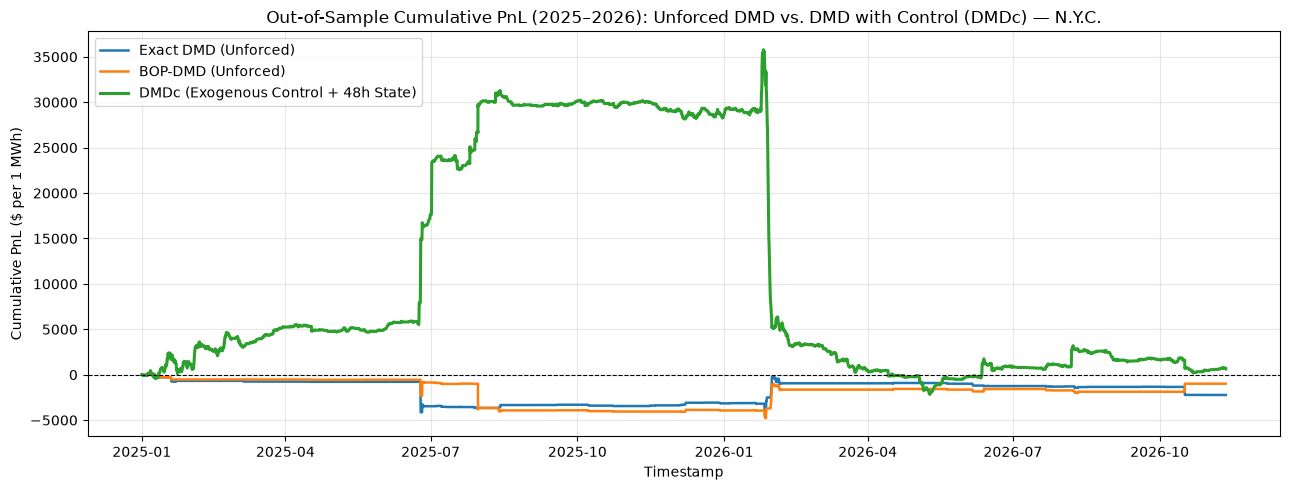

In [7]:
common_oos = diag_df.index.intersection(oos_dmdc_sig.index)

summary_rows = [
    compute_metrics(diag_df.loc[common_oos, "exact_sig"], diag_df.loc[common_oos, "realized_spread"], diag_df.loc[common_oos, "true_class"], "Exact DMD (Unforced)"),
    compute_metrics(diag_df.loc[common_oos, "bop_sig"], diag_df.loc[common_oos, "realized_spread"], diag_df.loc[common_oos, "true_class"], "BOP-DMD (Unforced)"),
    compute_metrics(oos_dmdc_sig.loc[common_oos], diag_df.loc[common_oos, "realized_spread"], diag_df.loc[common_oos, "true_class"], f"DMDc (Exog Control, alpha={int(best_alpha)})"),
]
comparison_df = pd.DataFrame(summary_rows)
display(comparison_df)

# Plot Cumulative PnL: Unforced DMD vs DMDc
dmdc_pnl = oos_dmdc_sig.loc[common_oos] * diag_df.loc[common_oos, "realized_spread"] - (oos_dmdc_sig.loc[common_oos] != 0) * FEE_PER_MWH

plt.figure(figsize=(13, 5))
plt.plot(common_oos, diag_df.loc[common_oos, "exact_pnl"].cumsum(), label="Exact DMD (Unforced)", linewidth=1.8)
plt.plot(common_oos, diag_df.loc[common_oos, "bop_pnl"].cumsum(), label="BOP-DMD (Unforced)", linewidth=1.8)
plt.plot(common_oos, dmdc_pnl.cumsum(), label=f"DMDc (Exogenous Control + 48h State)", linewidth=2.2, color="tab:green")
plt.axhline(0, color="black", linestyle="--", linewidth=0.8)
plt.title("Out-of-Sample Cumulative PnL (2025–2026): Unforced DMD vs. DMD with Control (DMDc) — N.Y.C.")
plt.ylabel("Cumulative PnL ($ per 1 MWh)")
plt.xlabel("Timestamp")
plt.legend(loc="upper left")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

=== Daily PnL Breakdown (Jan 20 – Feb 15, 2026) ===


,trades,net_dir,avg_state_term,avg_control_term,avg_dmdc_pred,avg_realized_spread,daily_pnl,cum_pnl_in_window
Time Stamp,,,,,,,,
2026-01-20,22,-14,0.181699,-7.671769,-7.490070,20.107500,-272.42,-272.42
2026-01-21,24,-24,-0.642338,-16.420876,-17.063214,1.202917,-40.87,-313.29
2026-01-22,24,-24,-0.896835,-26.259253,-27.156088,-4.155833,87.74,-225.55
2026-01-23,22,22,-0.120413,7.286127,7.165713,0.338750,38.02,-187.53
2026-01-24,24,-24,-0.281953,-28.323573,-28.605526,-264.021250,6324.51,6136.98
2026-01-25,20,-20,0.732031,-10.981170,-10.249139,-36.316250,218.92,6355.90
2026-01-26,22,-22,0.054233,-19.778050,-19.723816,171.277500,-3655.85,2700.05
2026-01-27,21,-13,-0.173147,-11.551470,-11.724618,316.954167,-3761.97,-1061.92
2026-01-28,21,-21,-0.818773,-23.919699,-24.738472,579.339167,-12703.05,-13764.97



=== Top 15 Single-Hour Losses in Jan–Feb 2026 ===


,realized_spread,dmdc_pred,state_term,control_term,dmdc_sig,dmdc_pnl,cum_pnl
Time Stamp,,,,,,,
2026-01-28 15:00:00,833.20,-28.809016,0.427885,-29.236900,-1,-833.70,19566.33
2026-01-28 22:00:00,779.66,-48.984392,-0.753543,-48.230849,-1,-780.16,16156.28
2026-01-28 14:00:00,752.56,-39.132729,-2.037685,-37.095044,-1,-753.06,20400.03
2026-01-28 23:00:00,733.84,-50.043011,-0.702046,-49.340966,-1,-734.34,15421.94
2026-01-28 12:00:00,722.37,-42.183444,-3.892096,-38.291348,-1,-722.87,21874.83
2026-01-28 13:00:00,721.24,-36.148036,0.350590,-36.498627,-1,-721.74,21153.09
2026-01-28 09:00:00,709.71,-34.862345,-0.930216,-33.932128,-1,-710.21,23999.14
2026-01-28 11:00:00,706.27,-44.525082,-3.742377,-40.782705,-1,-706.77,22597.70
2026-01-28 10:00:00,694.17,-42.308938,-2.189637,-40.119302,-1,-694.67,23304.47


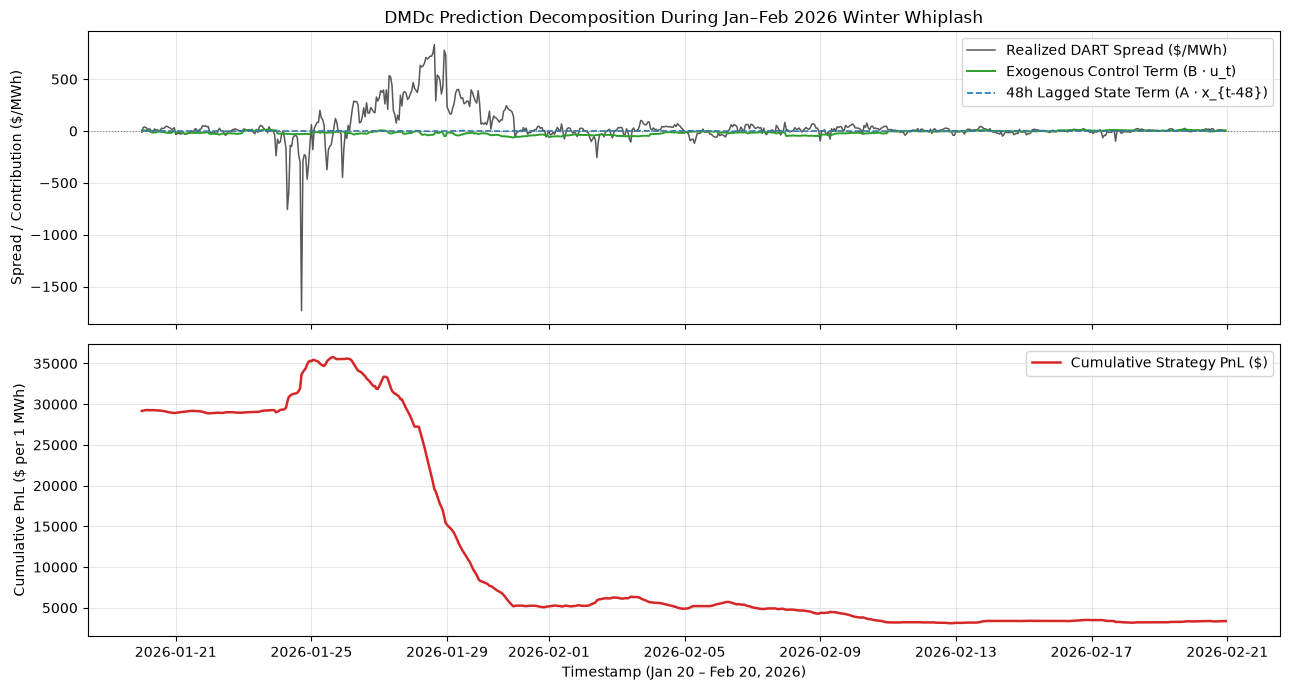

In [8]:
# === Exact Diagnostic Cell Using Cell 8 & 9 Variables ===
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. Decompose DMDc predictions into State term (A * x_{t-48}) vs. Exogenous Control term (B * u_t)
Xs_oos = sx.transform(X_prev.loc[oos_test_mask])
Us_oos = su.transform(U_curr.loc[oos_test_mask])

n_x = Xs_oos.shape[1]
nyc_col_idx = list(X_zones.columns).index(nyc_spread_col)
A_nyc = dmdc_model.coef_[nyc_col_idx, :n_x]
B_nyc = dmdc_model.coef_[nyc_col_idx, n_x:]
intercept_nyc = float(dmdc_model.intercept_[nyc_col_idx])

oos_idx = X_prev.index[oos_test_mask]
state_term_s = pd.Series(Xs_oos @ A_nyc, index=oos_idx)
control_term_s = pd.Series(Us_oos @ B_nyc + intercept_nyc, index=oos_idx)

# 2. Assemble aligned diagnostic DataFrame
decomp_df = pd.DataFrame({
    "realized_spread": diag_df.loc[common_oos, "realized_spread"],
    "dmdc_pred": oos_dmdc_pred_s.loc[common_oos],
    "state_term": state_term_s.loc[common_oos],
    "control_term": control_term_s.loc[common_oos],
    "dmdc_sig": oos_dmdc_sig.loc[common_oos],
    "dmdc_pnl": dmdc_pnl.loc[common_oos],
}, index=common_oos)
decomp_df["cum_pnl"] = decomp_df["dmdc_pnl"].cumsum()

# 3. Isolate Jan 20 – Feb 20, 2026 winter whiplash window
win_feb = decomp_df.loc["2026-01-20":"2026-02-20"].copy()

print("=== Daily PnL Breakdown (Jan 20 – Feb 15, 2026) ===")
daily_summary = win_feb.loc["2026-01-20":"2026-02-15"].resample("D").agg(
    trades=("dmdc_sig", lambda s: int((s != 0).sum())),
    net_dir=("dmdc_sig", "sum"),
    avg_state_term=("state_term", "mean"),
    avg_control_term=("control_term", "mean"),
    avg_dmdc_pred=("dmdc_pred", "mean"),
    avg_realized_spread=("realized_spread", "mean"),
    daily_pnl=("dmdc_pnl", "sum"),
)
daily_summary["cum_pnl_in_window"] = daily_summary["daily_pnl"].cumsum()
display(daily_summary)

print("\n=== Top 15 Single-Hour Losses in Jan–Feb 2026 ===")
display(
    win_feb.nsmallest(15, "dmdc_pnl")[
        ["realized_spread", "dmdc_pred", "state_term", "control_term", "dmdc_sig", "dmdc_pnl", "cum_pnl"]
    ]
)

# 4. Plot State vs. Exogenous Control vs. Realized Spread during the Crash
fig, axes = plt.subplots(2, 1, figsize=(13, 7), sharex=True)

axes[0].plot(win_feb.index, win_feb["realized_spread"], color="black", alpha=0.65, lw=1.1, label="Realized DART Spread ($/MWh)")
axes[0].plot(win_feb.index, win_feb["control_term"], color="tab:green", lw=1.4, label="Exogenous Control Term (B · u_t)")
axes[0].plot(win_feb.index, win_feb["state_term"], color="tab:blue", lw=1.2, ls="--", label="48h Lagged State Term (A · x_{t-48})")
axes[0].axhline(0, color="gray", lw=0.8, ls=":")
axes[0].set_ylabel("Spread / Contribution ($/MWh)")
axes[0].set_title("DMDc Prediction Decomposition During Jan–Feb 2026 Winter Whiplash")
axes[0].legend(loc="upper right")
axes[0].grid(True, alpha=0.3)

axes[1].plot(win_feb.index, win_feb["cum_pnl"], color="tab:red", lw=1.8, label="Cumulative Strategy PnL ($)")
axes[1].set_ylabel("Cumulative PnL ($ per 1 MWh)")
axes[1].set_xlabel("Timestamp (Jan 20 – Feb 20, 2026)")
axes[1].legend(loc="upper right")
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


## 6. Key Finding: Why Static `DMDc` Suffers Regime-Drift Drawdown in Jan–Feb 2026

While adding Day-Ahead exogenous forcing (`DMDc`) eliminates calm-regime threshold starvation (`58.8%` trade frequency vs. `1.6%` for unforced `BOP-DMD`) and generates steady gains through 2025, **fitting `[A, B]` once on `2020–2024` and freezing it across `2025–2026` creates severe vulnerability to structural regime drift**:
1. **State Dynamics Shrinkage (`alpha=5000`):** High regularization shrinks the 48-hour state transition matrix $\mathbf{A} \approx 0$, leaving predictions almost entirely governed by static exogenous weights $\mathbf{B}\mathbf{u}_t$.
2. **Winter Scarcity Inversion (`Jan 26–30, 2026`):** During the extreme cold snap, frozen `2020–2024` control weights predicted negative DART spreads (`-$20` to `-$50/MWh`, triggering `-1` DEC bids) right as Real-Time scarcity prices spiked to `+$500–$833/MWh`, erasing `~$37.9k` in cumulative PnL.

We export these static out-of-sample results to `dmdc_static_oos_results.parquet` to benchmark against **iteratively rolled, periodically refit `DMDc`** in Notebook 2.


In [9]:
# === Cell 9: Export Static DMDc Results & Bridge to Scheduled Refitting ===
static_export_df = pd.DataFrame({
    "realized_spread": diag_df.loc[common_oos, "realized_spread"],
    "true_class": diag_df.loc[common_oos, "true_class"],
    "exact_pred": diag_df.loc[common_oos, "exact_pred"],
    "exact_sig": diag_df.loc[common_oos, "exact_sig"],
    "exact_pnl": diag_df.loc[common_oos, "exact_pnl"],
    "bop_pred": diag_df.loc[common_oos, "bop_pred"],
    "bop_sig": diag_df.loc[common_oos, "bop_sig"],
    "bop_pnl": diag_df.loc[common_oos, "bop_pnl"],
    "dmdc_static_pred": oos_dmdc_pred_s.loc[common_oos],
    "dmdc_static_state_term": state_term_s.loc[common_oos],
    "dmdc_static_control_term": control_term_s.loc[common_oos],
    "dmdc_static_sig": oos_dmdc_sig.loc[common_oos],
    "dmdc_static_pnl": dmdc_pnl.loc[common_oos],
}, index=common_oos)

export_path = DATA_DIR / "dmdc_static_oos_results.parquet"
static_export_df.to_parquet(export_path)
print(f"Saved Static DMDc OOS benchmark to: {export_path} ({len(static_export_df):,} rows)")

peak_pnl = static_export_df["dmdc_static_pnl"].cumsum().max()
final_pnl = static_export_df["dmdc_static_pnl"].sum()
feb_loss = static_export_df.loc["2026-01-20":"2026-02-15", "dmdc_static_pnl"].sum()
print(f"\n[Static DMDc Takeaway]")
print(f"  • Pre-crash peak Cum PnL: ${peak_pnl:,.2f}")
print(f"  • Jan 20 – Feb 15, 2026 drawdown window PnL: ${feb_loss:,.2f}")
print(f"  • Final 2025–2026 Cum PnL: ${final_pnl:,.2f}")
print("  -> Motivation for Notebook 2: Freezing [A, B] in Dec 2024 leaves the linear control operator blind to 2025–2026 structural/fuel regime drift. Next, we test 1-hour iterative DMDc with periodic 30-day expanding-window refits.")


Saved Static DMDc OOS benchmark to: /Users/patrick/Documents/uw/me570-nyiso-sparse-sensing/notebooks/nyiso_data/merged_parquet/dmdc_static_oos_results.parquet (16,306 rows)

[Static DMDc Takeaway]
  • Pre-crash peak Cum PnL: $35,777.49
  • Jan 20 – Feb 15, 2026 drawdown window PnL: $-25,794.88
  • Final 2025–2026 Cum PnL: $630.27
  -> Motivation for Notebook 2: Freezing [A, B] in Dec 2024 leaves the linear control operator blind to 2025–2026 structural/fuel regime drift. Next, we test 1-hour iterative DMDc with periodic 30-day expanding-window refits.
